# EDA 1: day-ahead prices

Core zones only: DE_LU, FR and ES, read from the config by `group: core`. Hourly table (experiment H).

**Train data only.** Every figure and number uses delivery days before `splits.validation_start` (2026-06-23). No validation or test day is read.

How to read this notebook:

- Each code cell calls a function of `epf.eda.price_figures`. The command `python -m epf.eda.price_figures` calls the same functions and writes the figures to `reports/figures/`.
- Each cell prints the tables behind its figure. Every number in a finding below is copied from those tables.
- Prices are in EUR/MWh. Hours, weekdays, months and years are in market time (Europe/Berlin).
- A sentence that starts with "Guess:" is my reading of a cause. The data in this notebook does not test it.

In [1]:
from epf.config import load_config
from epf.eda import price_figures as figures

config = load_config()
prices = figures.load_core_prices(config)
figures.print_tables({"Train data, hourly table": figures.train_period(prices, config)})


Train data, hourly table
       hours        first_hour         last_hour  empty_prices
DE_LU  65519  2019-01-01 00:00  2026-06-22 23:00             0
FR     65519  2019-01-01 00:00  2026-06-22 23:00             0
ES     65519  2019-01-01 00:00  2026-06-22 23:00             0


The train set has 65519 hours per zone, from 2019-01-01 00:00 to 2026-06-22 23:00, and no empty price. 2026 is a part year.

## 1. Price distribution


Summary
       hours  mean    std     min    q01  q05   q25  median    q75    q95    q99     max  skew
DE_LU  65519 94.86  91.89 -500.00 -11.57 1.32 38.28   77.10 116.77 272.47 475.36  936.28  2.50
FR     65519 93.71 102.84 -496.86  -2.00 3.09 33.86   62.38 112.30 300.95 510.00 2987.78  3.03
ES     65519 80.17  64.02  -15.00  -0.62 0.84 36.22   62.60 111.34 208.10 277.45  700.00  1.45

Lowest and highest price, with the hour in market time
          min          min_time     max          max_time
DE_LU -500.00  2023-07-02 14:00  936.28  2024-12-12 17:00
FR    -496.86  2026-05-01 13:00 2987.78  2022-04-04 08:00
ES     -15.00  2025-05-11 16:00  700.00  2022-03-08 19:00

Price range of the histogram, and the hours outside it
       range_low  range_high  hours_below  hours_above
DE_LU     -55.64      678.27          137           75
FR        -55.64      678.27           60          121
ES        -55.64      678.27            0            1


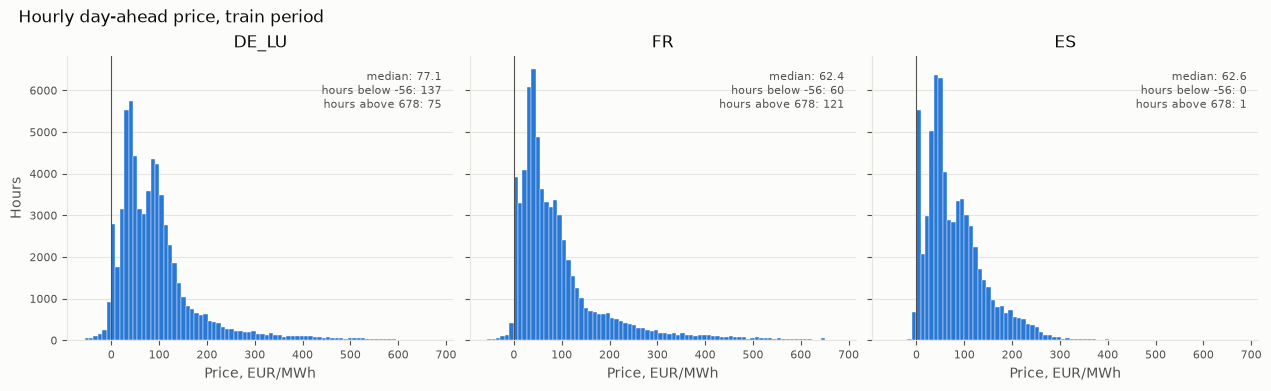

In [2]:
tables, figure = figures.distribution(prices, config)
figures.print_tables(tables)

**Finding.** The price is skewed to the right and has long tails on both sides.

- DE_LU has a median of 77.10 and a mean of 94.86. Its 1% quantile is -11.57 and its 99% quantile 475.36. The lowest price is -500.00 and the highest 936.28.
- FR has the longest upper tail: a maximum of 2987.78 on 2022-04-04 at 08:00, with a 99% quantile of 510.00. Its skew is 3.03.
- ES is the narrowest: from -15.00 to 700.00, with a skew of 1.45.
- The 5% quantile is close to zero in all three zones: 1.32, 3.09 and 0.84. Prices at and below zero are part of the target.
- So the project uses no log transform and no MAPE. Both break at zero and below.
- The histogram covers -55.64 to 678.27. It leaves out 137 hours below and 75 above in DE_LU, 60 and 121 in FR, and 0 and 1 in ES.
- The DE_LU histogram has two humps. Guess: the lower one is the years 2019 and 2020 and the upper one the years from 2023. Section 4 shows the level per year.

## 2. Price by hour of day


Median price
      DE_LU    FR    ES
hour                   
0     78.22 64.97 75.20
1     72.91 56.83 67.83
2     70.45 52.58 63.11
3     69.06 45.11 60.00
4     70.00 42.47 58.45
5     75.01 48.52 60.03
6     85.26 60.39 68.41
7     93.01 75.26 80.20
8     94.08 80.60 78.43
9     81.15 71.85 65.00
10    69.13 61.14 55.85
11    59.96 55.10 52.20
12    54.37 52.64 50.53
13    49.16 47.01 49.85
14    49.93 45.98 47.59
15    55.41 46.53 46.40
16    67.84 51.15 48.35
17    83.96 62.22 53.30
18    99.98 77.59 63.37
19   109.03 88.94 79.93
20   106.91 87.31 93.89
21    97.01 83.60 98.47
22    93.05 83.69 91.85
23    83.32 75.03 80.90

25% quantile of the price
      DE_LU    FR    ES
hour                   
0     35.67 34.63 40.09
1     33.31 30.62 36.12
2     32.06 27.92 34.07
3     30.44 24.30 32.51
4     30.93 21.51 32.00
5     33.72 26.30 33.50
6     41.78 32.84 37.90
7     48.89 40.73 43.98
8     50.02 43.09 44.14
9     44.97 40.47 39.97
10    37.52 34.45 32.10
11    33.02 30.01 26.15

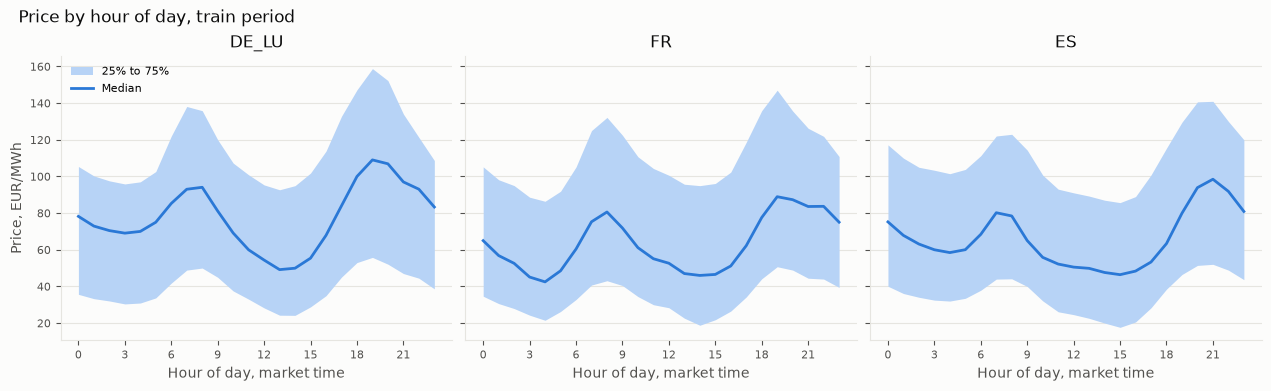

In [3]:
tables, figure = figures.by_hour(prices, config)
figures.print_tables(tables)

**Finding.** All three zones have a morning peak, a midday dip and an evening peak.

- DE_LU: the median is 94.08 at hour 8, falls to 49.16 at hour 13 and rises to 109.03 at hour 19.
- FR: 80.60 at hour 8, 45.98 at hour 14 and 88.94 at hour 19. Its lowest median is at night, 42.47 at hour 4.
- ES: the evening peak comes later, 98.47 at hour 21. The low is 46.40 at hour 15.
- The spread within one hour is larger than the difference between hours. In DE_LU at hour 19 the middle half of the prices runs from 55.82 to 158.85. The band mixes all years, so it also carries the level changes of section 4.
- Hour 2 has 2729 prices and every other hour 2730. On a 23-hour day hour 2 does not exist, and on a 25-hour day it counts twice.
- Guess: the midday dip comes from solar output. EDA 2 compares the price with the solar forecast.

## 3. Price by weekday


Median price
         DE_LU    FR    ES
weekday                   
Mon      80.14 65.00 66.40
Tue      84.06 69.92 73.05
Wed      83.75 70.00 69.77
Thu      82.98 68.81 69.00
Fri      80.80 68.67 67.60
Sat      65.91 52.33 53.69
Sun      52.41 43.74 47.58

25% quantile of the price
         DE_LU    FR    ES
weekday                   
Mon      42.08 35.90 39.04
Tue      43.99 38.71 41.69
Wed      44.48 38.51 41.03
Thu      42.91 37.87 40.53
Fri      42.05 37.44 39.05
Sat      31.07 28.29 30.29
Sun      21.98 18.43 23.54

75% quantile of the price
         DE_LU     FR     ES
weekday                     
Mon     123.19 115.91 115.00
Tue     127.49 119.31 115.81
Wed     125.36 118.59 114.18
Thu     122.89 118.59 115.99
Fri     118.06 115.56 114.94
Sat     104.31 102.60 104.87
Sun      99.66  95.24  97.67

Number of hours with a price
         DE_LU    FR    ES
weekday                   
Mon       9360  9360  9360
Tue       9360  9360  9360
Wed       9360  9360  9360
Thu       9360  9360

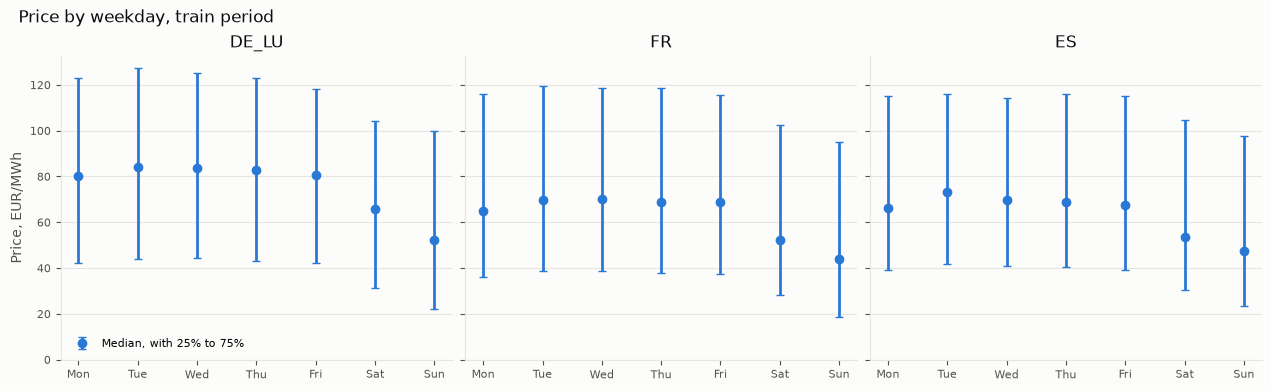

In [4]:
tables, figure = figures.by_weekday(prices, config)
figures.print_tables(tables)

**Finding.** Monday to Friday are alike, and the weekend is cheaper, Sunday most of all.

- DE_LU: the weekday medians lie between 80.14 and 84.06. Saturday is 65.91 and Sunday 52.41.
- FR: 65.00 to 70.00 on weekdays, 52.33 on Saturday and 43.74 on Sunday.
- ES: 66.40 to 73.05 on weekdays, 53.69 on Saturday and 47.58 on Sunday.
- The price follows a weekly cycle. That supports the seasonal naive baseline, which takes the same hour seven days earlier, and weekday features for LightGBM.
- Public holidays are not separated here. The `holidays` package is not installed yet.
- Sunday has 9359 hours and every other weekday 9360, because the clock changes fall on Sundays.

## 4. Mean price by year and month


Mean price per year (rows) and month (columns), DE_LU
         1      2      3      4      5      6      7      8      9      10     11     12
2019  49.39  42.82  30.63  36.96  37.84  32.52  39.69  36.85  35.75  36.94  41.00  31.97
2020  35.03  21.92  22.49  17.09  17.60  26.18  30.06  34.86  43.69  33.97  38.79  43.52
2021  52.81  48.70  47.16  53.61  53.35  74.08  81.37  82.70 128.37 139.49 176.15 221.06
2022 167.73 128.80 252.01 165.73 177.48 218.03 315.00 465.18 346.12 152.60 173.63 251.62
2023 117.83 128.31 102.52 100.74  81.72  94.76  77.61  94.32 100.72  87.38  91.12  68.52
2024  76.57  61.34  64.70  62.36  67.21  72.89  67.70  82.05  78.31  86.10 113.91 108.32
2025 114.14 128.52  94.73  77.94  67.34  63.99  87.80  76.99  83.51  84.40 101.88  93.47
2026 110.09  96.58  99.29  78.52  97.54  96.46      -      -      -      -      -      -

Mean price per year (rows) and month (columns), FR
         1      2      3      4      5      6      7      8      9      10     11     12
201

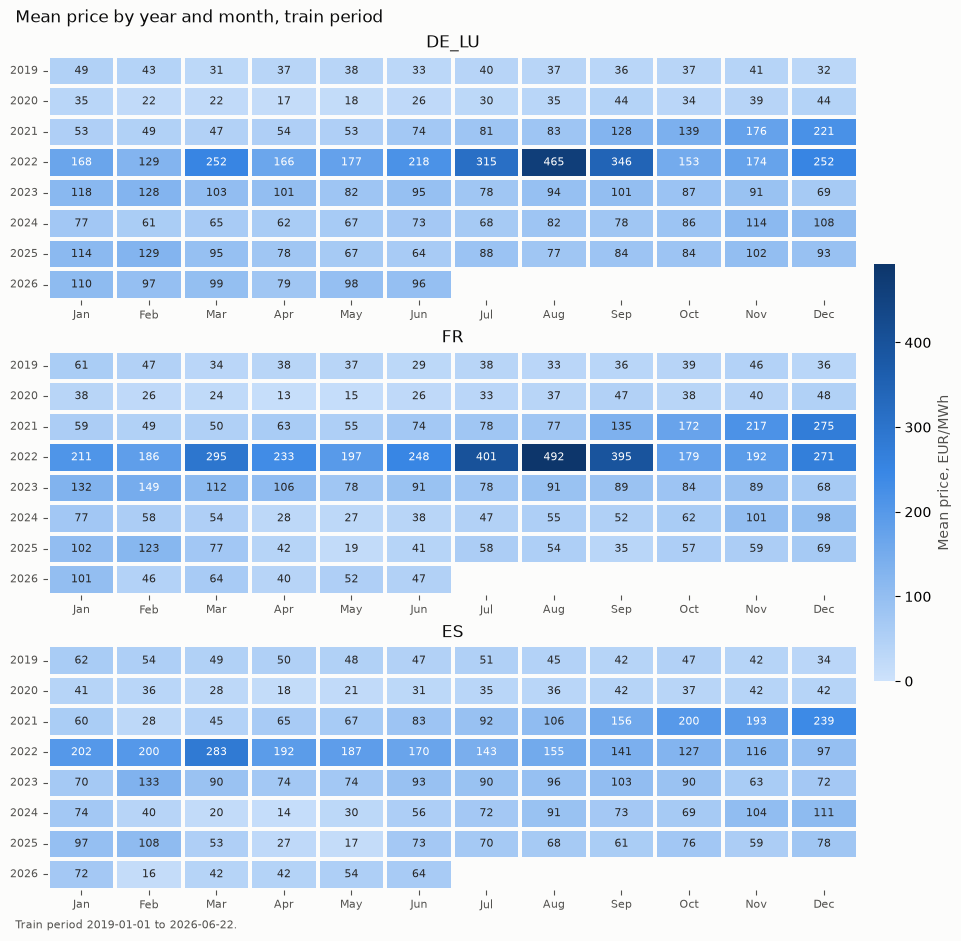

In [5]:
tables, figure = figures.by_month_year(prices, config)
figures.print_tables(tables)

**Finding.** The level moves far more between years than between the months of one year.

- DE_LU: the monthly mean runs from 17.09 in April 2020 to 465.18 in August 2022.
- FR peaks at 492.49 in August 2022. ES peaks earlier and lower, at 283.39 in March 2022.
- No month is high or low in every year. In DE_LU, January is 35.03 in 2020, 167.73 in 2022 and 110.09 in 2026.
- From 2024 the spring months are low in FR and ES. FR has 28.23 and 27.17 in April and May 2024 and 19.38 in May 2025. ES has 13.67 in April 2024 and 16.93 in May 2025.
- A model trained on all years sees very different price levels. This notebook only states the level. The 2022 regime is analysed in EDA 2.
- 2026 covers 1 January to 22 June, so its June value is the mean of 22 days.

## 5. Spikes

Rule (DECISIONS entry 38): an hour is a spike when its price is above the mean of the 672 hours (28 days) before it plus 3 standard deviations of those hours. Only upward spikes count. The first 672 hours of 2019 have no full window and are not judged. Both numbers are in the config under `eda`. They are conventions and were not tuned.


Summary
       hours_judged  hours_flagged  share_percent  days_flagged
DE_LU         64847            486           0.75           194
FR            64847            493           0.76           167
ES            64847            305           0.47           108

Hours per year
      DE_LU   FR  ES
year                
2019     11   15   0
2020     56   70   1
2021     55   69  55
2022    101  171  77
2023     33   27   7
2024     89   47  63
2025    100   66  44
2026     41   28  58

Hours per month
       DE_LU  FR  ES
month               
1         56  46  46
2         12   6  25
3         61  72  94
4          9  21  39
5          7  10  22
6         27  77  27
7         11  24   2
8         42  28  12
9         61  19   6
10        33  28  22
11       108  98   3
12        59  64   7

Hours per hour of day
      DE_LU  FR  ES
hour               
0         0   2   6
1         0   0   3
2         0   0   1
3         0   0   1
4         0   0   1
5         0   0   1
6         5   5

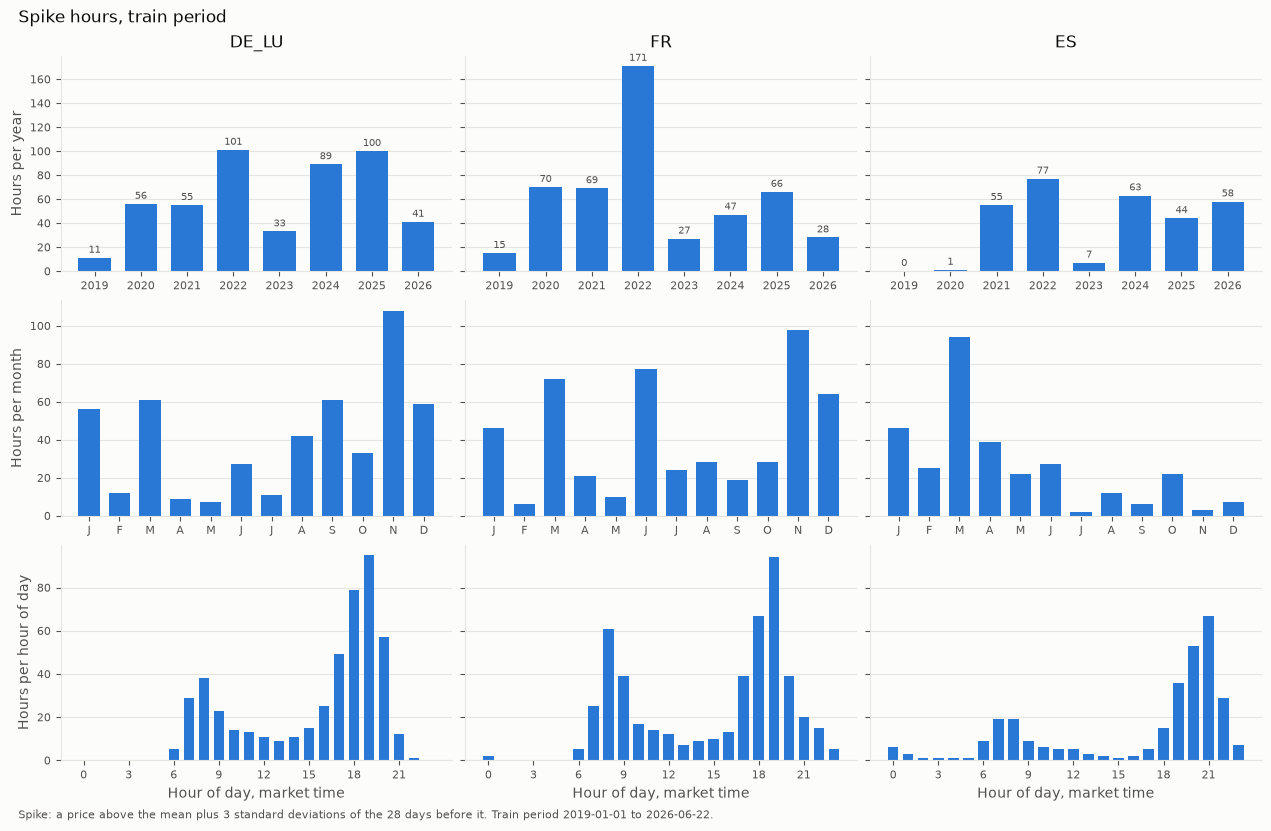

In [6]:
tables, figure = figures.spikes(prices, config)
figures.print_tables(tables)

**Finding.** Spikes are rare, occur in most years and fall on the morning and evening peaks.

- The rule flags 486 of 64847 judged hours in DE_LU (0.75%), 493 in FR (0.76%) and 305 in ES (0.47%). They fall on 194, 167 and 108 delivery days.
- The most spike hours are in 2022: 101 in DE_LU, 171 in FR and 77 in ES. But 2024 and 2025 have 89 and 100 in DE_LU, so the rule does not only mark the crisis year.
- By hour: DE_LU has 95 spike hours at hour 19 and none from hour 0 to hour 5. FR has 94 at hour 19 and 61 at hour 8. ES is later, with 67 at hour 21.
- By month: DE_LU has 108 spike hours in November and 7 in May.
- The months January to June count eight years and July to December seven, because 2026 is a part year. Read the month panel with that in mind.
- Guess: these are hours of high demand with little wind and solar. EDA 2 looks at the drivers.

## 6. Negative prices


Summary
       hours_judged  hours_flagged  share_percent  days_flagged  hours_at_zero
DE_LU         65519           2346           3.58           417            191
FR            65519           1616           2.47           311            530
ES            65519           1428           2.18           230           1002

Hours per year
      DE_LU   FR   ES
year                 
2019    211   27    0
2020    298  102    0
2021    139   64    0
2022     69    4    0
2023    301  147    0
2024    457  352  247
2025    576  513  556
2026    295  407  625

Hours per month
       DE_LU   FR   ES
month                 
1         89   16   15
2        117   36  148
3        206   78  175
4        344  350  362
5        416  371  373
6        320  332  201
7        186  121   43
8        181  135   35
9        143   89   50
10       144   42   21
11        23    6    5
12       177   40    0

Hours per hour of day
      DE_LU   FR   ES
hour                 
0        41    2    0
1        59

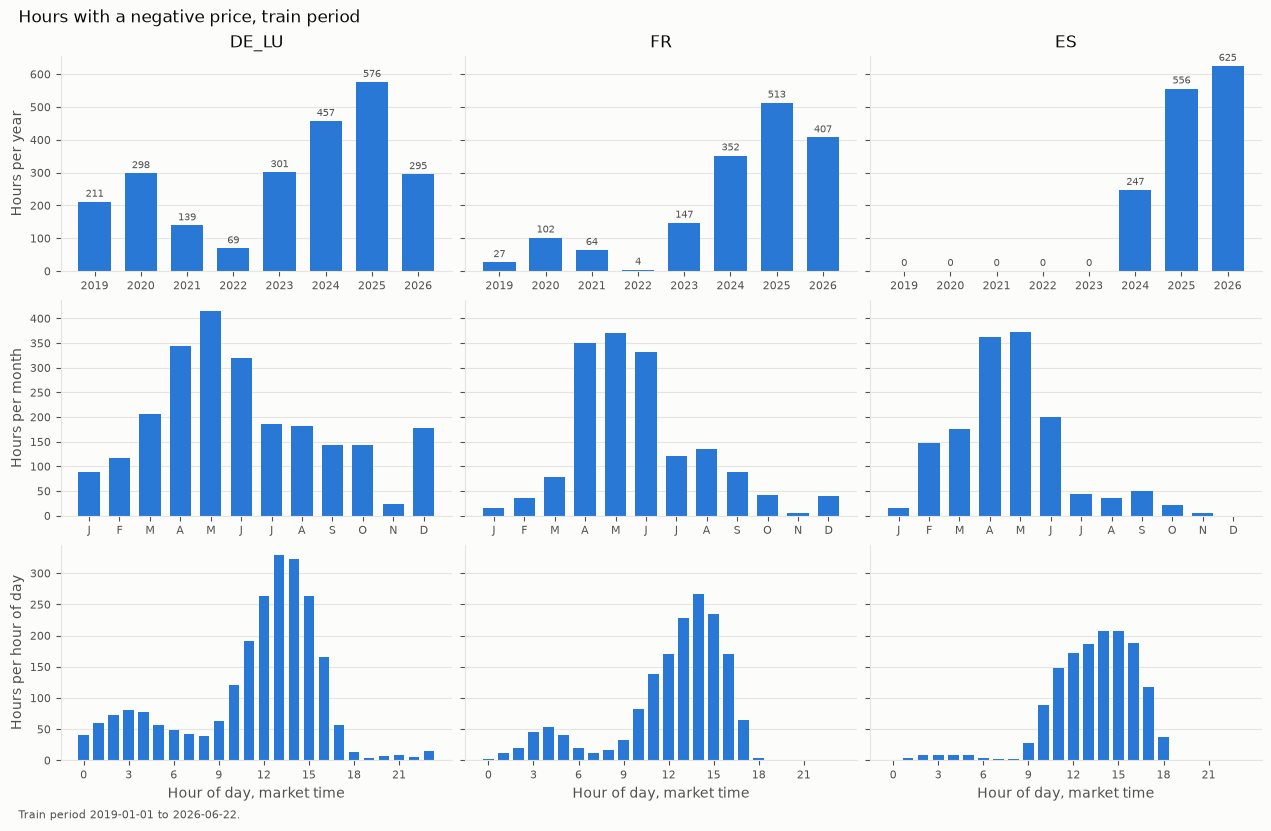

In [7]:
tables, figure = figures.negative_prices(prices, config)
figures.print_tables(tables)

**Finding.** Negative prices are common, are growing and occur around midday in spring.

- DE_LU has 2346 hours below zero (3.58% of the train hours), FR 1616 (2.47%) and ES 1428 (2.18%). They fall on 417, 311 and 230 delivery days.
- The count grows. DE_LU: 211 in 2019 and 576 in 2025. FR: 27 in 2019 and 513 in 2025. ES had none before 2024, then 247, 556 and already 625 in 2026 up to 22 June.
- By hour: DE_LU has 329 at hour 13, FR 267 at hour 14 and ES 208 at hours 14 and 15. From hour 19 to hour 22 no zone has more than 9.
- By month: May has the most in every zone: 416 in DE_LU, 371 in FR and 373 in ES. The part year 2026 adds to January to June only.
- Prices of exactly zero come on top: 191 hours in DE_LU, 530 in FR and 1002 in ES.
- The lowest prices are -500.00 in DE_LU (2023-07-02 at 14:00), -496.86 in FR (2026-05-01 at 13:00) and -15.00 in ES.
- The recent train years differ from the early ones, most of all in ES. The validation and test sets come after these recent years, so a model must handle prices at and below zero.
- Guess: these are hours with much solar output and low demand. EDA 2 checks this against the forecasts.

## Not in this notebook

EDA 2 covers the price against load, wind and solar, hourly against 15-minute prices, the 2022 regime and the Swedish zones.